# Predicting Football Player Market Values from Point-in-Time Performance Data

**Research question:** can a player's recent playing time, output, age, position and league predict their Transfermarkt market value on a given date, using only information available on that date? We compare a gradient-boosted tree model (XGBoost) against a linear model (Ridge) and a simple group-median baseline, all evaluated on valuations from a later period than the training data.

## Setup

This cell imports the libraries and reads the project's fixed settings (the random seed, the train/test split date, the prediction cap and the list of excluded features) directly from `src/models.py`. Reading them from the code instead of typing them here means the notebook can never disagree with the pipeline that produced the results.

In [1]:
import ast
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

NOTEBOOK_START = time.perf_counter()

MODELS_SRC = Path("src/models.py").read_text()
module = ast.parse(MODELS_SRC)
constants = {}
for node in ast.walk(module):
    if isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name):
        name = node.targets[0].id
        if name in {"SEED", "LOG_PRED_FLOOR", "LOG_PRED_CEILING", "SNAPSHOT_FEATURES", "split_date",
                    "FEATURE_SET_FULL", "FEATURE_SET_CLEAN"}:
            constants[name] = eval(compile(ast.Expression(node.value), "src/models.py", "eval"), {"np": np})

SEED = constants["SEED"]
SPLIT_DATE = pd.Timestamp(constants["split_date"])
LOG_PRED_FLOOR = constants["LOG_PRED_FLOOR"]
LOG_PRED_CEILING = constants["LOG_PRED_CEILING"]
SNAPSHOT_FEATURES = constants["SNAPSHOT_FEATURES"]
FEATURE_SET_FULL = constants["FEATURE_SET_FULL"]
FEATURE_SET_CLEAN = constants["FEATURE_SET_CLEAN"]

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def eur(x):
    return f"€{x:,.0f}"

def eur_m(x):
    sign = "-" if x < 0 else ""
    return f"{sign}€{abs(x) / 1e6:,.2f}M"

def eur_signed_m(x):
    return ("+" if x >= 0 else "") + eur_m(x)

def bias_word(x):
    return "under-predicts" if x > 0 else "over-predicts"

display(Markdown(
    f"Settings read from `src/models.py`: seed **{SEED}**, split date **{SPLIT_DATE:%Y-%m-%d}**, "
    f"log prediction cap **[{LOG_PRED_FLOOR}, {LOG_PRED_CEILING:.4f}]** "
    f"(**{eur(np.exp(LOG_PRED_FLOOR))}** to **{eur(np.exp(LOG_PRED_CEILING))}**), "
    f"and **{len(SNAPSHOT_FEATURES)}** excluded snapshot features."
))

Matplotlib is building the font cache; this may take a moment.


Settings read from `src/models.py`: seed **42**, split date **2024-01-01**, log prediction cap **[8.5, 19.3370]** (**€4,915** to **€250,000,000**), and **5** excluded snapshot features.

## Data snapshot

Here we load the processed dataset that the pipeline built: one row per player valuation, with the features computed as of that valuation date. We report how many valuations and players it covers and show a few random rows, so the reader can see what a single training example looks like.

In [2]:
df = pd.read_parquet("data/processed_market_valuations.parquet")
df["valuation_date"] = pd.to_datetime(df["valuation_date"])

display(Markdown(
    f"The dataset has **{len(df):,}** valuations of **{df['player_id'].nunique():,}** unique players, "
    f"dated from **{df['valuation_date'].min():%Y-%m-%d}** to **{df['valuation_date'].max():%Y-%m-%d}**, "
    f"with **{df.shape[1]}** columns."
))

sample_cols = ["valuation_date", "player_name", "age", "position", "league_tier", "club_name",
               "minutes_last_365d", "goals_last_365d", "assists_last_365d", "market_value_in_eur"]
df[sample_cols].sample(5, random_state=SEED).sort_values("valuation_date")

The dataset has **547,653** valuations of **40,883** unique players, dated from **2014-01-01** to **2026-06-12**, with **39** columns.

,valuation_date,player_name,age,position,league_tier,club_name,minutes_last_365d,goals_last_365d,assists_last_365d,market_value_in_eur
110330,2017-06-28,Glen Johnson,32.85,Defender,Tier 1 - Big 5,Stoke City,2045.0,0.0,0.0,5000000
382266,2023-03-21,Mattia Destro,32.00,Attack,Tier 1 - Big 5,FC Empoli,845.0,1.0,0.0,1500000
404650,2023-06-27,Théo Pellenard,29.31,Defender,Tier 1 - Big 5,AJ Auxerre,99.0,0.0,0.0,1000000
457887,2024-06-17,Tchoca,20.46,Defender,Tier 3 - Other First Tier,Sport Club Corinthians Paulista,0.0,0.0,0.0,300000
480050,2024-12-27,Pepelu,26.38,Midfield,Tier 1 - Big 5,Valencia CF,3153.0,8.0,3.0,15000000


## Target variable: raw vs log market value

The next cell plots the distribution of market values in euros and after taking the natural log. A few superstars are worth hundreds of times more than a typical player, so a model trained on raw euros would spend most of its effort on those few rows; the log scale makes the target far more symmetric and makes errors relative (being off by half matters equally for cheap and expensive players).

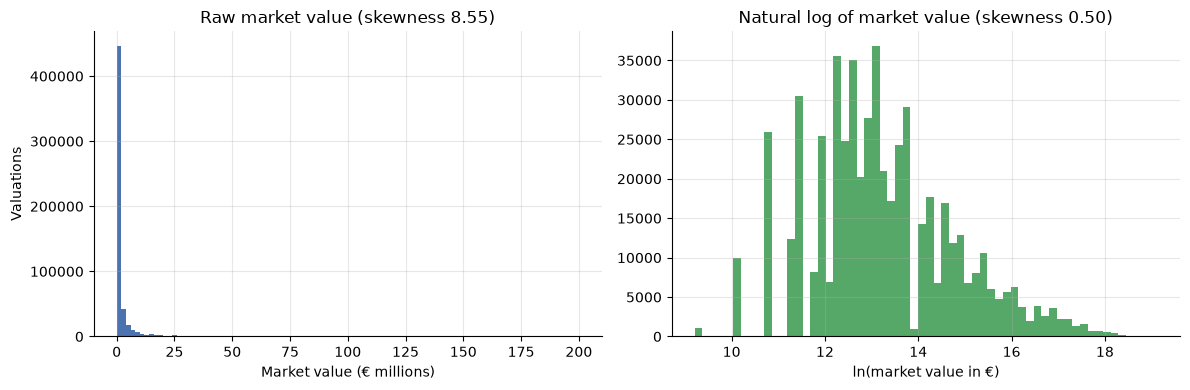

- Raw values are heavily right-skewed: skewness **8.55**, and the mean (**€2,330,222**) is **4.7x** the median (**€500,000**).
- After the log transform the skewness falls to **0.50**, close to symmetric, which is why every model is trained on log value.

In [3]:
values = df["market_value_in_eur"].astype(float)
log_values = np.log(values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(values / 1e6, bins=100, color="#4C72B0")
axes[0].set_title(f"Raw market value (skewness {values.skew():.2f})")
axes[0].set_xlabel("Market value (€ millions)")
axes[0].set_ylabel("Valuations")
axes[1].hist(log_values, bins=60, color="#55A868")
axes[1].set_title(f"Natural log of market value (skewness {log_values.skew():.2f})")
axes[1].set_xlabel("ln(market value in €)")
plt.tight_layout()
plt.show()

display(Markdown(
    f"- Raw values are heavily right-skewed: skewness **{values.skew():.2f}**, and the mean "
    f"(**{eur(values.mean())}**) is **{values.mean() / values.median():.1f}x** the median (**{eur(values.median())}**).\n"
    f"- After the log transform the skewness falls to **{log_values.skew():.2f}**, close to symmetric, "
    f"which is why every model is trained on log value."
))

## Chronological train/test split

This cell splits the valuations by date: everything before the split date is used for training and everything on or after it is held out for testing. This mimics the real use case, where a model built on the past is asked to value players in the future.

In [4]:
train = df[df["valuation_date"] < SPLIT_DATE]
test = df[df["valuation_date"] >= SPLIT_DATE]

overall_bias = json.loads(Path("models/overall_bias.json").read_text())
assert len(test) == overall_bias["test_rows"], "test rows differ from the pipeline's saved test set"

split_table = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Rule": [f"valuation_date < {SPLIT_DATE:%Y-%m-%d}", f"valuation_date >= {SPLIT_DATE:%Y-%m-%d}"],
    "First date": [f"{train['valuation_date'].min():%Y-%m-%d}", f"{test['valuation_date'].min():%Y-%m-%d}"],
    "Last date": [f"{train['valuation_date'].max():%Y-%m-%d}", f"{test['valuation_date'].max():%Y-%m-%d}"],
    "Rows": [f"{len(train):,}", f"{len(test):,}"],
    "Share of rows": [f"{len(train) / len(df):.1%}", f"{len(test) / len(df):.1%}"],
    "Players": [f"{train['player_id'].nunique():,}", f"{test['player_id'].nunique():,}"],
})
display(split_table.style.hide(axis="index"))

both = len(set(train["player_id"]) & set(test["player_id"]))
display(Markdown(
    f"**{both:,}** players appear in both sets; the split separates *dates*, not players, "
    f"so the model is judged on how well it values known and new players later in time."
))

Set,Rule,First date,Last date,Rows,Share of rows,Players
Train,valuation_date < 2024-01-01,2014-01-01,2023-12-31,"435,947",79.6%,"37,586"
Test,valuation_date >= 2024-01-01,2024-01-01,2026-06-12,"111,706",20.4%,"21,792"


**18,495** players appear in both sets; the split separates *dates*, not players, so the model is judged on how well it values known and new players later in time.

**Why not a random split?** A player is valued many times over a career, and neighbouring valuations of the same player are nearly identical. With a random split, the test set would contain valuations sandwiched between training valuations of the same player, so the model could effectively look up the answer from the future and the past around it. It would also learn market-wide price levels from later years (for example, inflation in transfer values) and then be "tested" on earlier dates. A date-based split removes both shortcuts, and the hyper-parameter search inside the training set uses `TimeSeriesSplit` for the same reason.

## Leakage audit and ablation

Some features were not truly available on the valuation date: they come from a single current snapshot of `players.csv` or `clubs.csv`. The next cell reads the list of these features and the reason for each directly from the comments in `src/models.py`, and checks, using the data itself, how one of them changes over time.

In [5]:
lines = MODELS_SRC.splitlines()
start = next(i for i, line in enumerate(lines) if line.startswith("SNAPSHOT_FEATURES = ["))
reasons, pending = {}, []
for line in lines[start + 1:]:
    stripped = line.strip()
    if stripped.startswith("]"):
        break
    if stripped.startswith("#"):
        pending.append(stripped.lstrip("# ").strip())
    else:
        match = re.match(r'"([^"]+)"', stripped)
        if match:
            reasons[match.group(1)] = " ".join(pending)
            pending = []
assert list(reasons) == SNAPSHOT_FEATURES

display(pd.DataFrame({"Dropped feature": list(reasons), "Why it is not point-in-time": list(reasons.values())})
        .style.hide(axis="index"))

contract_by_year = df.groupby(df["valuation_date"].dt.year)["contract_days_remaining"].median()
first_year, last_year = contract_by_year.index.min(), contract_by_year.index.max()
display(Markdown(
    f"Evidence from the data: the median `contract_days_remaining` is **{contract_by_year[first_year]:,.0f}** days "
    f"for {first_year} valuations but **{contract_by_year[last_year]:,.0f}** days for {last_year}. A real contract "
    f"rarely has that long left; old valuations are being measured against contracts signed years later."
))

Dropped feature,Why it is not point-in-time
contract_days_remaining,"Days from the valuation date to the expiry of the player's *current* contract in players.csv, not the contract in force at the valuation, so old valuations see contracts signed later."
has_contract_info,Whether players.csv has a current contract expiry date; this partly encodes whether the player is still under contract at the snapshot date.
club_squad_size,"Squad size from the current row of clubs.csv (one row per club), not the squad at the valuation."
club_foreigners_percentage,Share of foreign players from the current row of clubs.csv.
club_national_team_players,Number of current national-team players from the current row of clubs.csv.


Evidence from the data: the median `contract_days_remaining` is **3,793** days for 2014 valuations but **757** days for 2026. A real contract rarely has that long left; old valuations are being measured against contracts signed years later.

To measure how much these features matter, the pipeline trained every model twice: once with them ("full") and once without them ("clean"). The cell below shows both versions from `models/leakage_ablation.csv` and computes how much worse the clean XGBoost model is. The headline results in the rest of this notebook all use the clean models.

In [6]:
ablation = pd.read_csv("models/leakage_ablation.csv")
metric_cols = ["Log RMSE", "Log MAE", "Euro RMSE", "Euro MAE"]
model_rows = ablation[~ablation["Model"].str.startswith("%")].copy()
model_rows[metric_cols] = model_rows[metric_cols].astype(float)

shown = model_rows.copy()
for col in ["Log RMSE", "Log MAE"]:
    shown[col] = shown[col].map("{:.4f}".format)
for col in ["Euro RMSE", "Euro MAE"]:
    shown[col] = shown[col].map(eur)
display(shown.style.hide(axis="index"))

xgb_full = model_rows[(model_rows["Model"] == "Main XGBoost Regressor") & (model_rows["Feature Set"] == FEATURE_SET_FULL)].iloc[0]
xgb_clean = model_rows[(model_rows["Model"] == "Main XGBoost Regressor") & (model_rows["Feature Set"] == FEATURE_SET_CLEAN)].iloc[0]
worse = {c: (xgb_clean[c] - xgb_full[c]) / xgb_full[c] * 100 for c in metric_cols}

stored = ablation[ablation["Model"].str.startswith("%")].iloc[0]
for c in metric_cols:
    assert abs(float(str(stored[c]).rstrip("%")) - worse[c]) < 0.006

ridge = model_rows[model_rows["Model"] == "Baseline Ridge Regression"]
ridge_same = (ridge[metric_cols].nunique() == 1).all()

display(Markdown(
    "**How to read this.** Without the snapshot features, the XGBoost model is "
    + ", ".join(f"**{worse[c]:.2f}%** worse on {c}" for c in metric_cols)
    + ". This tells us how much the model *relied* on those features; it does not say that the full model's score "
      "was inflated by exactly that amount. Some of the lost accuracy may be genuine signal (a contract running down "
      "really does lower a player's value), and we cannot separate the genuine part from the leaked part with this data, "
      "so we report the clean model as the honest headline."
    + (" The two Ridge rows are identical because the Ridge baseline never used any of the snapshot features."
       if ridge_same else "")
))

Model,Feature Set,Log RMSE,Log MAE,Euro RMSE,Euro MAE
Naive Baseline (Position x Tier Median),Position x league tier medians (no model features),1.4904,1.1488,"€9,047,330","€2,795,267"
Baseline Ridge Regression,Full (with snapshot features),1.1562,0.9050,"€7,157,729","€2,244,637"
Baseline Ridge Regression,Clean (snapshot features dropped),1.1562,0.9050,"€7,157,729","€2,244,637"
Main XGBoost Regressor,Full (with snapshot features),0.8508,0.6473,"€4,193,906","€1,432,443"
Main XGBoost Regressor,Clean (snapshot features dropped),0.9108,0.6981,"€4,779,167","€1,600,833"


**How to read this.** Without the snapshot features, the XGBoost model is **7.06%** worse on Log RMSE, **7.84%** worse on Log MAE, **13.96%** worse on Euro RMSE, **11.76%** worse on Euro MAE. This tells us how much the model *relied* on those features; it does not say that the full model's score was inflated by exactly that amount. Some of the lost accuracy may be genuine signal (a contract running down really does lower a player's value), and we cannot separate the genuine part from the leaked part with this data, so we report the clean model as the honest headline. The two Ridge rows are identical because the Ridge baseline never used any of the snapshot features.

## Model comparison (headline, clean feature set)

This cell compares the headline predictors on the test period: a naive baseline that predicts the training median for the player's position and league tier, a Ridge linear regression, XGBoost, and XGBoost with a smearing correction (explained in the "Where the model fails" section). A useful model must clearly beat the naive baseline, otherwise the features add nothing beyond "what kind of player in which league".

Model,Log RMSE,Log MAE,Euro RMSE,Euro MAE
Naive Baseline (Position x Tier Median),1.4904,1.1488,"€9,047,330","€2,795,267"
Baseline Ridge Regression,1.1562,0.9050,"€7,157,729","€2,244,637"
Main XGBoost Regressor,0.9108,0.6981,"€4,779,167","€1,600,833"
Main XGBoost Regressor (Smear-Corrected),0.9108,0.6981,"€4,493,754","€1,653,781"


Model,Log RMSE,Log MAE,Euro RMSE,Euro MAE
% Improvement (XGBoost vs Ridge Baseline),21.22%,22.87%,33.23%,28.68%
% Improvement (XGBoost vs Naive Baseline),38.89%,39.23%,47.18%,42.73%


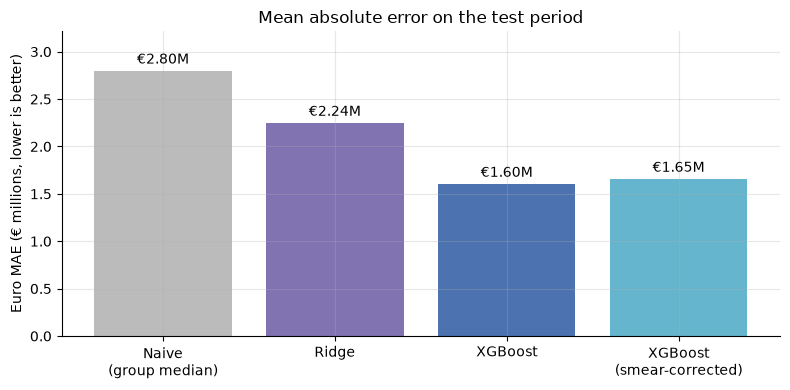

XGBoost's typical error is **€1,600,833**, against **€2,244,637** for Ridge and **€2,795,267** for the naive baseline, i.e. **42.7%** lower than the naive baseline. In log terms the Log MAE of **0.698** means a typical prediction is off by a factor of about **2.01x** in either direction.

In [7]:
comparison = pd.read_csv("models/model_comparison_metrics.csv")
headline = comparison[~comparison["Model"].str.startswith("%")].copy()
headline[metric_cols] = headline[metric_cols].astype(float)
improvements = comparison[comparison["Model"].str.startswith("%")]

shown = headline.copy()
for col in ["Log RMSE", "Log MAE"]:
    shown[col] = shown[col].map("{:.4f}".format)
for col in ["Euro RMSE", "Euro MAE"]:
    shown[col] = shown[col].map(eur)
display(shown.style.hide(axis="index"))
display(improvements.style.hide(axis="index"))

short_names = {"Naive Baseline (Position x Tier Median)": "Naive\n(group median)",
               "Baseline Ridge Regression": "Ridge",
               "Main XGBoost Regressor": "XGBoost",
               "Main XGBoost Regressor (Smear-Corrected)": "XGBoost\n(smear-corrected)"}
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(headline["Model"].map(short_names), headline["Euro MAE"] / 1e6,
              color=["#BBBBBB", "#8172B2", "#4C72B0", "#64B5CD"])
ax.bar_label(bars, labels=[eur_m(v) for v in headline["Euro MAE"]], padding=3)
ax.set_ylabel("Euro MAE (€ millions, lower is better)")
ax.set_title("Mean absolute error on the test period")
ax.set_ylim(0, headline["Euro MAE"].max() / 1e6 * 1.15)
plt.tight_layout()
plt.show()

m = headline.set_index("Model")
xgb, naive, rdg = m.loc["Main XGBoost Regressor"], m.loc["Naive Baseline (Position x Tier Median)"], m.loc["Baseline Ridge Regression"]
display(Markdown(
    f"XGBoost's typical error is **{eur(xgb['Euro MAE'])}**, against **{eur(rdg['Euro MAE'])}** for Ridge and "
    f"**{eur(naive['Euro MAE'])}** for the naive baseline, i.e. **{(1 - xgb['Euro MAE'] / naive['Euro MAE']):.1%}** lower "
    f"than the naive baseline. In log terms the Log MAE of **{xgb['Log MAE']:.3f}** means a typical prediction is off by a "
    f"factor of about **{np.exp(xgb['Log MAE']):.2f}x** in either direction."
))

## Feature importance

The next cell plots the features that the clean XGBoost model relied on most, measured by "gain" (how much each feature's splits reduced the training error in total). Importance shows what the model uses, not what causes market value, so the bullets below are descriptions of the model, not claims about football.

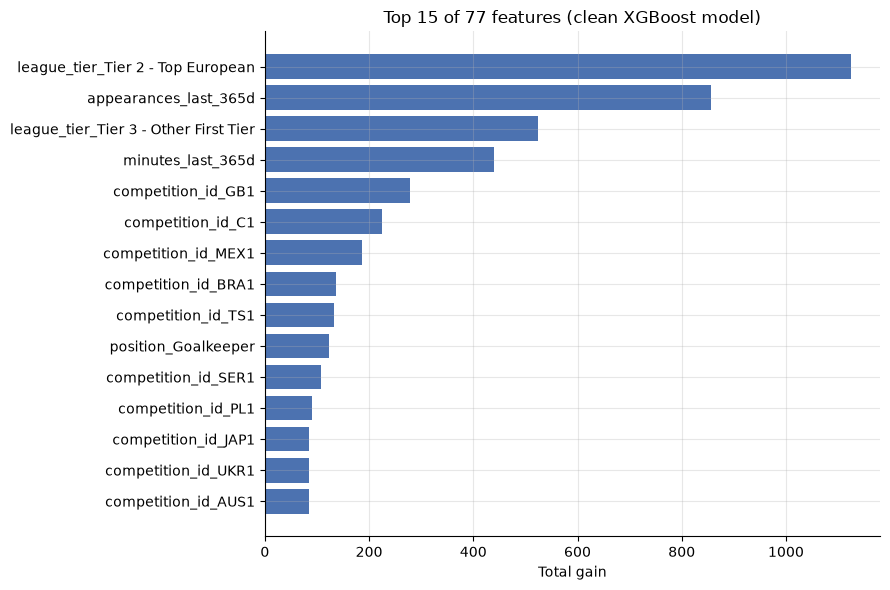

- **League and competition features carry the most gain (65.2%).** The single most important feature is `league_tier_Tier 2 - Top European` (18.1% of total gain); league or competition indicators together account for **65.2%**, so knowing which market a player is priced in does much of the work.
- **Playing time carries more gain than scoring.** Minutes and appearances hold **22.5%** of the gain versus **3.0%** for goals and assists. One reading (not tested here) is that being trusted with minutes is a broader value signal than goals, which only some positions produce.
- **Importance is concentrated.** The top 15 features carry **72.1%** of the gain; the first age feature ranks **#22**, and age-related features together hold **1.5%**.

In [8]:
importances = pd.read_csv("models/feature_importances.csv").sort_values("gain", ascending=False)
TOP_N = 15
top = importances.head(TOP_N).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["feature"], top["gain"], color="#4C72B0")
ax.set_xlabel("Total gain")
ax.set_title(f"Top {TOP_N} of {len(importances)} features (clean XGBoost model)")
plt.tight_layout()
plt.show()

total_gain = importances["gain"].sum()
def family(feature):
    if feature.startswith(("league_tier_", "competition_id_")):
        return "league and competition"
    if any(k in feature for k in ("minutes", "appearances")):
        return "playing time"
    if any(k in feature for k in ("goals", "assists", "contributions")):
        return "goal output"
    if feature.startswith("age"):
        return "age"
    return "other"
family_share = importances.groupby(importances["feature"].map(family))["gain"].sum() / total_gain
leader = importances.iloc[0]
top_family = family_share.drop("other").idxmax()
top_share = importances.head(TOP_N)["gain"].sum() / total_gain
ranked = importances.reset_index(drop=True)
age_rank = int(ranked.index[ranked["feature"].str.startswith("age")].min()) + 1
time_vs_goals = "more" if family_share["playing time"] > family_share["goal output"] else "less"

display(Markdown(
    f"- **{top_family.capitalize()} features carry the most gain ({family_share[top_family]:.1%}).** The single most "
    f"important feature is `{leader['feature']}` ({leader['gain'] / total_gain:.1%} of total gain); league or competition "
    f"indicators together account for **{family_share['league and competition']:.1%}**, so knowing which market a player is "
    f"priced in does much of the work.\n"
    f"- **Playing time carries {time_vs_goals} gain than scoring.** Minutes and appearances hold "
    f"**{family_share['playing time']:.1%}** of the gain versus **{family_share['goal output']:.1%}** for goals and assists. "
    f"One reading (not tested here) is that being trusted with minutes is a broader value signal than goals, which only "
    f"some positions produce.\n"
    f"- **Importance is concentrated.** The top {TOP_N} features carry **{top_share:.1%}** of the gain; the first age feature "
    f"ranks **#{age_rank}**, and age-related features together hold **{family_share['age']:.1%}**."
))

## Where the model fails

Average errors hide where the model is systematically wrong, so this cell breaks the test-set errors down by age band and league tier. It also introduces the smearing correction: predicting in log space and converting back with `exp()` gives a typical (median-like) value, which is systematically below the average, so the pipeline multiplies every euro prediction by one global "smearing factor" estimated on a validation fold.

Smearing factor: **1.5044** (estimated on 108,986 validation rows dated 2022-03-31 to 2023-12-31). Over the whole test set the mean bias (actual minus predicted) goes from **+€1.04M** uncorrected to **-€0.03M** after smearing.

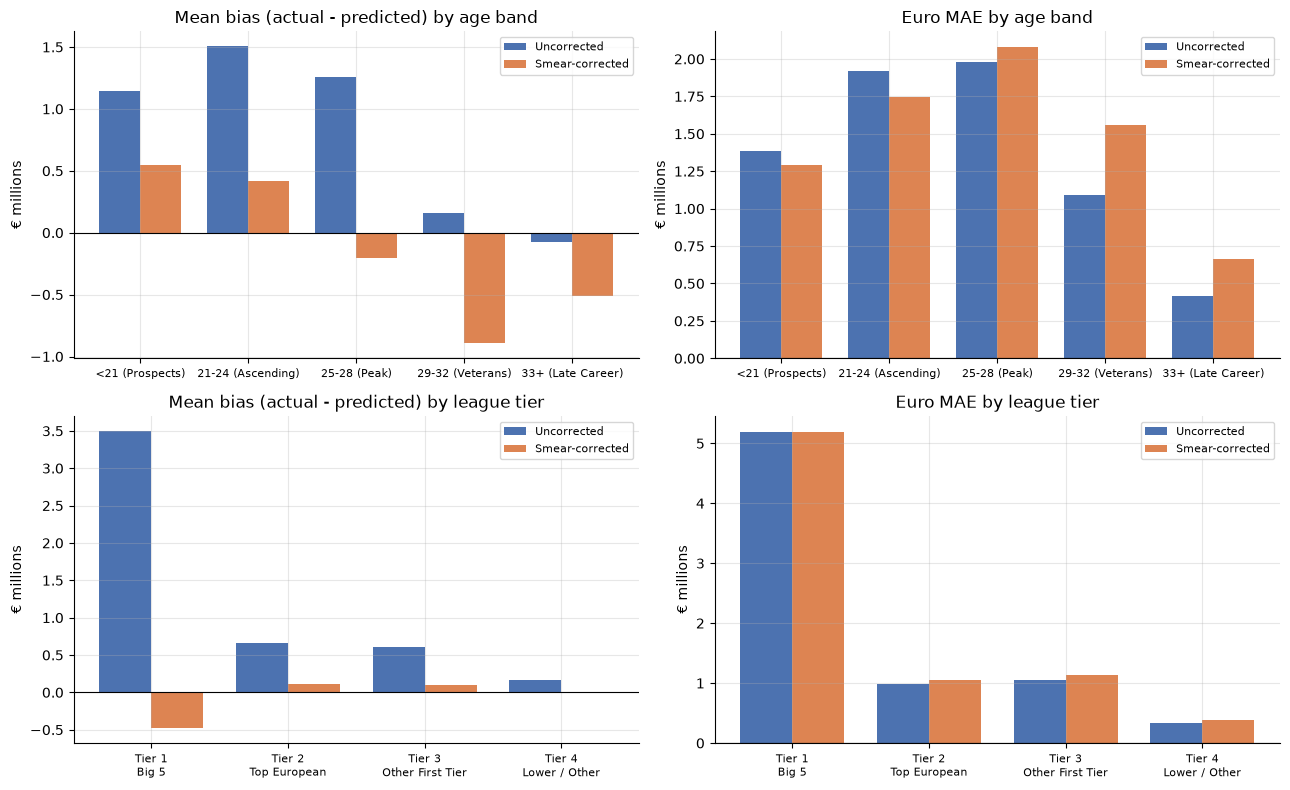

- **Tier 1 - Big 5**: the model under-predicts by **+€3.50M** on average before smearing, but after multiplying by 1.5044 it over-predicts (**-€0.48M**): the sign flips.
- 25-28 (Peak): +€1.26M uncorrected, -€0.20M smear-corrected (sign flips).
- 29-32 (Veterans): +€0.16M uncorrected, -€0.89M smear-corrected (sign flips).
- Tier 4 - Lower / Other: +€0.17M uncorrected, -€0.01M smear-corrected (sign flips).
- In log terms the largest relative errors are for **<21 (Prospects)** (Log MAE 0.906), and the strongest systematic bias is for **33+ (Late Career)** (log bias -0.344, the model over-predicts).

**One global factor fixes the overall bias but not segment bias.** Multiplying every prediction by the same 1.5044 brings the overall average close to zero, but it cannot raise Tier 1 - Big 5 predictions more than Tier 4 - Lower / Other ones, so segments that were biased in different directions stay biased, and some cross over to the other side.

In [9]:
smearing = json.loads(Path("models/smearing_factor.json").read_text())
factor = smearing["smearing_factor"]
display(Markdown(
    f"Smearing factor: **{factor:.4f}** (estimated on {smearing['fold_validation_rows']:,} validation rows dated "
    f"{smearing['fold_validation_start']} to {smearing['fold_validation_end']}). Over the whole test set the mean bias "
    f"(actual minus predicted) goes from **{eur_signed_m(overall_bias['mean_bias_eur_uncorrected'])}** uncorrected to "
    f"**{eur_signed_m(overall_bias['mean_bias_eur_smeared'])}** after smearing."
))

by_age = pd.read_csv("models/residual_analysis_by_age.csv")
by_age["segment"] = by_age["age_band"].str.slice(3)
by_tier = pd.read_csv("models/residual_analysis_by_tier.csv")
by_tier["segment"] = by_tier["league_tier"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (label, seg) in enumerate([("age band", by_age), ("league tier", by_tier)]):
    x = np.arange(len(seg))
    w = 0.38
    for col, (metric, title) in enumerate([("Mean_Bias_EUR", "Mean bias (actual - predicted)"),
                                           ("MAE_EUR", "Euro MAE")]):
        ax = axes[row, col]
        ax.bar(x - w / 2, seg[f"{metric}_Uncorrected"] / 1e6, w, label="Uncorrected", color="#4C72B0")
        ax.bar(x + w / 2, seg[f"{metric}_Smeared"] / 1e6, w, label="Smear-corrected", color="#DD8452")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(seg["segment"].str.replace(" - ", "\n"), fontsize=8)
        ax.set_ylabel("€ millions")
        ax.set_title(f"{title} by {label}")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

segments = pd.concat([by_age, by_tier])
flips = segments[np.sign(segments["Mean_Bias_EUR_Uncorrected"]) != np.sign(segments["Mean_Bias_EUR_Smeared"])]
tier1 = by_tier.iloc[0]
lines = [
    f"- **{tier1['segment']}**: the model {bias_word(tier1['Mean_Bias_EUR_Uncorrected'])} by "
    f"**{eur_signed_m(tier1['Mean_Bias_EUR_Uncorrected'])}** on average before smearing, but after multiplying by "
    f"{factor:.4f} it {bias_word(tier1['Mean_Bias_EUR_Smeared'])} (**{eur_signed_m(tier1['Mean_Bias_EUR_Smeared'])}**): "
    + ("the sign flips." if np.sign(tier1["Mean_Bias_EUR_Uncorrected"]) != np.sign(tier1["Mean_Bias_EUR_Smeared"])
       else "the sign does not flip.")
]
for _, r in flips.iterrows():
    if r["segment"] != tier1["segment"]:
        lines.append(f"- {r['segment']}: {eur_signed_m(r['Mean_Bias_EUR_Uncorrected'])} uncorrected, "
                     f"{eur_signed_m(r['Mean_Bias_EUR_Smeared'])} smear-corrected (sign flips).")
worst_age = by_age.loc[by_age["MAE_Log"].idxmax()]
worst_bias_age = by_age.loc[by_age["Mean_Bias_Log"].abs().idxmax()]
lines.append(
    f"- In log terms the largest relative errors are for **{worst_age['segment']}** (Log MAE {worst_age['MAE_Log']:.3f}), "
    f"and the strongest systematic bias is for **{worst_bias_age['segment']}** (log bias {worst_bias_age['Mean_Bias_Log']:+.3f}, "
    f"the model {bias_word(worst_bias_age['Mean_Bias_Log'])})."
)
display(Markdown(
    "\n".join(lines)
    + f"\n\n**One global factor fixes the overall bias but not segment bias.** Multiplying every prediction by the same "
      f"{factor:.4f} brings the overall average close to zero, but it cannot raise {by_tier.iloc[0]['segment']} predictions "
      f"more than {by_tier.iloc[-1]['segment']} ones, "
      f"so segments that were biased in different directions stay biased, and some cross over to the other side."
))

## Example predictions

To make the numbers concrete, this cell picks individual test valuations: the most accurate prediction for a regular player (at least the median playing time among players who played) in each of the highest league tiers, the largest miss among uncapped predictions, and (if any exist) the largest miss among predictions that hit the cap. For each one we compare the player's actual value with the values of similar players (same position and tier in the test set), because players who look typical for their group are easy and outliers are hard.

In [10]:
preds = pd.read_parquet("models/test_predictions.parquet")
preds["capped"] = (preds["log_predicted"] >= LOG_PRED_CEILING - 1e-9) | (preds["log_predicted"] <= LOG_PRED_FLOOR + 1e-9)
preds["group_pct"] = preds.groupby(["position", "league_tier"])["actual_value_eur"].rank(pct=True)
order = ["abs_residual_log", "player_id", "valuation_date"]

share_no_minutes = (preds["minutes_last_365d"] == 0).mean()
regular_minutes = preds.loc[preds["minutes_last_365d"] > 0, "minutes_last_365d"].median()
regulars = preds[preds["minutes_last_365d"] >= regular_minutes]
tiers = sorted(preds["league_tier"].unique())
accurate = [regulars[regulars["league_tier"] == t].sort_values(order, kind="mergesort").iloc[0] for t in tiers[:3]]

PLURAL = {"Attack": "attackers", "Midfield": "midfielders", "Defender": "defenders", "Goalkeeper": "goalkeepers"}
def ordinal(p):
    n = int(round(p))
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"
def minutes_text(mins):
    return ("no recorded minutes in the previous year, for example after an injury or a move from a league outside the data"
            if mins == 0 else f"{mins:,.0f} minutes in the previous year")
uncapped_miss = preds[~preds["capped"]].sort_values(order, ascending=[False, True, True], kind="mergesort").iloc[0]
capped_rows = preds[preds["capped"]]
second_miss = (capped_rows.sort_values(["abs_residual_eur", "player_id", "valuation_date"], ascending=[False, True, True], kind="mergesort").iloc[0]
               if len(capped_rows) else
               preds[~preds["capped"]].sort_values(order, ascending=[False, True, True], kind="mergesort").iloc[1])

def summary(r, kind):
    ratio = r["predicted_value_eur"] / r["actual_value_eur"]
    head = (f"**{kind}: {r['player_name']}** ({r['position']}, age {r['age']:.1f}, {r['club_name']}, {r['league_tier']}, "
            f"{r['valuation_date']:%Y-%m-%d}): actual **{eur(r['actual_value_eur'])}**, predicted **{eur(r['predicted_value_eur'])}** "
            f"({ratio:.2f}x actual).")
    pct, mins = r["group_pct"] * 100, r["minutes_last_365d"]
    group = f"{PLURAL.get(r['position'], r['position'])} in their tier"
    if kind == "Accurate":
        why = (f"Why easy: their value sits at the {ordinal(pct)} percentile of {group} and they played "
               f"{mins:,.0f} minutes in the previous year (median among test players who played: {regular_minutes:,.0f}), so they are a "
               f"regular player with a typical profile, which the features describe well; a match this close is still partly luck.")
    elif r["capped"]:
        at_top = r["log_predicted"] >= LOG_PRED_CEILING - 1e-9
        bound = eur(np.exp(LOG_PRED_CEILING if at_top else LOG_PRED_FLOOR))
        why = (f"Why hard: the raw prediction was {'above' if at_top else 'below'} the cap, so it was clipped to {bound}; at the "
               f"top {100 - pct:.1f}% of {group}, this player sits at the extreme edge of the values the model was "
               f"trained on, where there are very few similar examples to learn from.")
    else:
        direction = "far above" if ratio < 1 else "far below"
        why = (f"Why hard: their actual value is {direction} what their playing record suggests (value at the {ordinal(pct)} "
               f"percentile of {group}, with {minutes_text(mins)}); the gap is driven by something the features "
               f"cannot see, such as potential, injury history, or reputation.")
    return head + " " + why

examples = [(r, "Accurate") for r in accurate] + [(uncapped_miss, "Inaccurate"), (second_miss, "Inaccurate")]
display(Markdown("\n\n".join(f"{i}. " + summary(r, k) for i, (r, k) in enumerate(examples, start=1))))
display(Markdown(f"Test predictions at the cap: **{int(preds['capped'].sum()):,}** of **{len(preds):,}**. "
                 f"**{share_no_minutes:.1%}** of test valuations have no recorded minutes in the previous year, so accurate "
                 f"examples are picked from players with at least {regular_minutes:,.0f} minutes, the median among those who played."))

1. **Accurate: Donovan Léon** (Goalkeeper, age 32.6, AJ Auxerre, Tier 1 - Big 5, 2025-06-03): actual **€1,000,000**, predicted **€999,821** (1.00x actual). Why easy: their value sits at the 44th percentile of goalkeepers in their tier and they played 2,880 minutes in the previous year (median among test players who played: 1,005), so they are a regular player with a typical profile, which the features describe well; a match this close is still partly luck.

2. **Accurate: Khellven** (Defender, age 23.8, PFK CSKA Moskva, Tier 2 - Top European, 2024-12-12): actual **€5,000,000**, predicted **€4,998,633** (1.00x actual). Why easy: their value sits at the 93rd percentile of defenders in their tier and they played 2,423 minutes in the previous year (median among test players who played: 1,005), so they are a regular player with a typical profile, which the features describe well; a match this close is still partly luck.

3. **Accurate: Kye Rowles** (Defender, age 26.9, D.C. United, Tier 3 - Other First Tier, 2025-06-05): actual **€1,200,000**, predicted **€1,192,033** (0.99x actual). Why easy: their value sits at the 69th percentile of defenders in their tier and they played 1,980 minutes in the previous year (median among test players who played: 1,005), so they are a regular player with a typical profile, which the features describe well; a match this close is still partly luck.

4. **Inaccurate: Gabriel Carvalho** (Attack, age 18.8, Al-Qadsiah Saudi Football Club, Tier 3 - Other First Tier, 2026-06-04): actual **€12,000,000**, predicted **€98,883** (0.01x actual). Why hard: their actual value is far above what their playing record suggests (value at the 98th percentile of attackers in their tier, with no recorded minutes in the previous year, for example after an injury or a move from a league outside the data); the gap is driven by something the features cannot see, such as potential, injury history, or reputation.

5. **Inaccurate: Lamine Yamal** (Attack, age 18.4, FC Barcelona, Tier 1 - Big 5, 2025-12-12): actual **€200,000,000**, predicted **€250,000,000** (1.25x actual). Why hard: the raw prediction was above the cap, so it was clipped to €250,000,000; at the top 0.1% of attackers in their tier, this player sits at the extreme edge of the values the model was trained on, where there are very few similar examples to learn from.

Test predictions at the cap: **2** of **111,706**. **56.3%** of test valuations have no recorded minutes in the previous year, so accurate examples are picked from players with at least 1,005 minutes, the median among those who played.

## Limitations and next steps

The final cell lists the main limitations, matching the Limitations section of `README.md`, with every figure recomputed from the files loaded above. These are the reasons the test metrics should be read as a careful estimate rather than a guarantee.

In [11]:
HIGH_VALUE_EUR, YOUNG_AGE = 100_000_000, 25
model_below = pd.read_csv("models/overvalued_top20.csv")
assert (model_below["value_delta_eur"] < 0).all()
n_100m = int((model_below["actual_value_eur"] >= HIGH_VALUE_EUR).sum())
n_u25 = int((model_below["age"] < YOUNG_AGE).sum())

n_test_zero = int((test["minutes_last_365d"] == 0).sum())
assert n_test_zero == int((preds["minutes_last_365d"] == 0).sum())
zero_share_by_tier = (test["minutes_last_365d"] == 0).groupby(test["league_tier"]).mean()
zero_by_tier = "; ".join(f"{tier} {share:.1%}" for tier, share in zero_share_by_tier.items())
zero_table = preds.groupby(preds["minutes_last_365d"] == 0).agg(
    euro_mae=("abs_residual_eur", "mean"), log_mae=("abs_residual_log", "mean"), avg_actual=("actual_value_eur", "mean"))
zero, some = zero_table.loc[True], zero_table.loc[False]
zero_reading = (
    f" Euro MAE is lower for zero-minute rows ({eur(zero['euro_mae'])} vs {eur(some['euro_mae'])}) only because those "
    f"players have lower market values (average actual {eur(zero['avg_actual'])} vs {eur(some['avg_actual'])}); relative "
    f"error is higher (Log MAE {zero['log_mae']:.4f} vs {some['log_mae']:.4f}), so the model is less accurate in relative "
    f"terms where it has no recent playing time."
    if zero["euro_mae"] < some["euro_mae"] and zero["log_mae"] > some["log_mae"] and zero["avg_actual"] < some["avg_actual"]
    else ""
)

limitations = [
    f"**Snapshot features removed.** {', '.join(f'`{f}`' for f in SNAPSHOT_FEATURES)} come from the current player "
    f"and club tables of the raw data, not from values as of the valuation date; the headline model excludes them (median contract days left: "
    f"{contract_by_year[first_year]:,.0f} in {first_year} vs {contract_by_year[last_year]:,.0f} in {last_year}). "
    f"The XGBoost model is {worse['Log RMSE']:.2f}% worse on Log RMSE without them.",
    "**Position, sub-position, height and foot are assumed stable.** They are also current snapshot values, kept because "
    "they rarely change during a career; the club at each valuation is likewise assumed, not documented, to be correct.",
    "**Imputation leakage inside CV folds.** Missing heights are filled with training-set medians by position; the "
    "`TimeSeriesSplit` folds used for tuning and for the smearing factor reuse medians from the whole training set, a small leak "
    "of later training data into earlier folds (the test set is not affected).",
    f"**Predictions are capped.** Log predictions are clipped to [{LOG_PRED_FLOOR}, {LOG_PRED_CEILING:.4f}], i.e. "
    f"{eur(np.exp(LOG_PRED_FLOOR))} to {eur(np.exp(LOG_PRED_CEILING))}; {int(preds['capped'].sum()):,} test predictions hit the cap.",
    "**Crowdsourced target.** Transfermarkt market values are community estimates, not transfer fees, so the model learns "
    "the crowd's opinion, including its biases.",
    f"**No potential or hype signal.** The features cover playing time, output, age, position, height, foot and league only. "
    f"Of the {len(model_below)} players the model values furthest below the market, {n_100m} are valued at "
    f"{eur(HIGH_VALUE_EUR)} or more and {n_u25} are under {YOUNG_AGE}.",
    f"**Most test valuations have no recent playing time.** {n_test_zero:,} of the {len(test):,} test valuations "
    f"({n_test_zero / len(test):.1%}) have `minutes_last_365d` = 0, i.e. no recorded minutes in the 365 days before the "
    f"valuation (by league tier: {zero_by_tier}). Hypothesis (not verified here): the appearance data covers fewer of the "
    f"competitions these players play in, so some zeros mean \"not recorded\" rather than \"did not play\"." + zero_reading,
    f"**Static snapshot.** Valuations run through {df['valuation_date'].max():%Y-%m-%d}; the data is not refreshed. "
    f"(The README also reports the latest match date in the raw match data, which this notebook does not load.)",
]
next_steps = [
    "Rebuild contract and club features from dated records (historical contracts, squad lists per season) so they can be used without leakage.",
    "Compute imputation medians inside each fold to remove the remaining small leak.",
    "Add signals for potential and reputation, e.g. youth-international caps, minutes trend, or search interest, dated to the valuation.",
    "Fit segment-specific smearing factors (by league tier) instead of one global factor.",
]
display(Markdown("**Limitations**\n\n" + "\n".join(f"- {x}" for x in limitations)
                 + "\n\n**Next steps**\n\n" + "\n".join(f"- {x}" for x in next_steps)))
display(Markdown(f"_Notebook body ran in {time.perf_counter() - NOTEBOOK_START:.1f} seconds._"))

**Limitations**

- **Snapshot features removed.** `contract_days_remaining`, `has_contract_info`, `club_squad_size`, `club_foreigners_percentage`, `club_national_team_players` come from the current player and club tables of the raw data, not from values as of the valuation date; the headline model excludes them (median contract days left: 3,793 in 2014 vs 757 in 2026). The XGBoost model is 7.06% worse on Log RMSE without them.
- **Position, sub-position, height and foot are assumed stable.** They are also current snapshot values, kept because they rarely change during a career; the club at each valuation is likewise assumed, not documented, to be correct.
- **Imputation leakage inside CV folds.** Missing heights are filled with training-set medians by position; the `TimeSeriesSplit` folds used for tuning and for the smearing factor reuse medians from the whole training set, a small leak of later training data into earlier folds (the test set is not affected).
- **Predictions are capped.** Log predictions are clipped to [8.5, 19.3370], i.e. €4,915 to €250,000,000; 2 test predictions hit the cap.
- **Crowdsourced target.** Transfermarkt market values are community estimates, not transfer fees, so the model learns the crowd's opinion, including its biases.
- **No potential or hype signal.** The features cover playing time, output, age, position, height, foot and league only. Of the 20 players the model values furthest below the market, 14 are valued at €100,000,000 or more and 11 are under 25.
- **Most test valuations have no recent playing time.** 62,908 of the 111,706 test valuations (56.3%) have `minutes_last_365d` = 0, i.e. no recorded minutes in the 365 days before the valuation (by league tier: Tier 1 - Big 5 14.4%; Tier 2 - Top European 34.2%; Tier 3 - Other First Tier 91.6%; Tier 4 - Lower / Other 85.2%). Hypothesis (not verified here): the appearance data covers fewer of the competitions these players play in, so some zeros mean "not recorded" rather than "did not play". Euro MAE is lower for zero-minute rows (€618,759 vs €2,866,876) only because those players have lower market values (average actual €951,229 vs €5,971,544); relative error is higher (Log MAE 0.7451 vs 0.6374), so the model is less accurate in relative terms where it has no recent playing time.
- **Static snapshot.** Valuations run through 2026-06-12; the data is not refreshed. (The README also reports the latest match date in the raw match data, which this notebook does not load.)

**Next steps**

- Rebuild contract and club features from dated records (historical contracts, squad lists per season) so they can be used without leakage.
- Compute imputation medians inside each fold to remove the remaining small leak.
- Add signals for potential and reputation, e.g. youth-international caps, minutes trend, or search interest, dated to the valuation.
- Fit segment-specific smearing factors (by league tier) instead of one global factor.

_Notebook body ran in 0.9 seconds._